In [1]:

# ==========================================
# GEMMA 4 BENCHMARK CONFIGURATION
# ==========================================

import json
import time
import numpy as np
import pandas as pd
import ollama

from pathlib import Path
from datetime import datetime
from tqdm.auto import tqdm

BASE_DIR = Path(
    r"C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS"
)

DATASET_FILE = (
    BASE_DIR
    / "malay_cleaned_dataset"
    / "malay_evaluation_dataset.jsonl"
)

RESULT_DIR = BASE_DIR / "results" / "gemma" / "prompt_v2"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

FULL_RESULTS_FILE = RESULT_DIR / "full_results_gemma_v2.jsonl"
FULL_FAILED_FILE = RESULT_DIR / "full_failed_gemma_v2.jsonl"

MODEL_NAME = "gemma4:31b"

TEMPERATURE = 0
SEED = 42
NUM_PREDICT = 1024

GENERATION_OPTIONS = {
    "temperature": TEMPERATURE,
    "seed": SEED,
    "num_predict": NUM_PREDICT
}

FULL_RESULTS_FILE = (
    RESULT_DIR / "full_results_gemma_v2.jsonl"
)

FULL_FAILED_FILE = (
    RESULT_DIR / "full_failed_gemma_v2.jsonl"
)

print("Gemma configuration loaded.")
print("Model:", MODEL_NAME)
print("Dataset:", DATASET_FILE)
print("Output directory:", RESULT_DIR)


Gemma configuration loaded.
Model: gemma4:31b
Dataset: C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\malay_cleaned_dataset\malay_evaluation_dataset.jsonl
Output directory: C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\gemma\prompt_v2


C:\AI\rocm-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

df = pd.read_json(
    DATASET_FILE,
    lines=True
)

print("Total records:", len(df))
print("\nRecords by domain:")
display(df["domain"].value_counts())

assert len(df) == 3448


Total records: 3448

Records by domain:


domain
Sentimen News    980
Penukaran Kod    799
Terjemahan       712
Sentimen         682
Campuran Kod     275
Name: count, dtype: int64

In [3]:
# ==========================================
# PROMPT CONFIGURATION
# ==========================================

PROMPTS = {

"Campuran Kod": """
Anda ialah pembantu yang menjana respons
berdasarkan konteks perbualan harian.

TUGAS:
Anda akan diberikan satu ujaran, soalan atau
mesej daripada seseorang.

Hasilkan DUA respons yang sesuai untuk membalas
input tersebut:

1. FORMAL:
   Gunakan Bahasa Melayu formal, baku dan sopan.

2. TIDAK FORMAL:
   Gunakan Bahasa Melayu santai dan semula jadi
   seperti perbualan harian.

ARAHAN PENTING:
- Fahami maksud dan konteks input terlebih dahulu.
- Jawab soalan atau berikan respons yang sesuai
  terhadap mesej yang diberikan.
- Jangan mengolah semula ayat input.
- Jangan menterjemahkan input.
- Jangan mengulang input sebagai jawapan.
- Pastikan kedua-dua respons benar-benar menjawab
  input yang diberikan.
- Kedua-dua respons mesti menyampaikan maksud
  jawapan yang sama tetapi menggunakan gaya
  bahasa yang berbeza.
- Jangan tambah penerangan atau ulasan.

FORMAT OUTPUT:
FORMAL: [Jawapan formal]
TIDAK FORMAL: [Jawapan tidak formal]

INPUT:
{input}
""",

"Penukaran Kod": """
Anda ialah pembantu yang menjana respons
berdasarkan konteks komunikasi profesional.

TUGAS:
Anda akan diberikan satu ujaran, soalan atau
mesej daripada seseorang.

Hasilkan DUA respons yang sesuai untuk membalas
input tersebut:

1. FORMAL:
   Gunakan Bahasa Melayu yang formal, baku,
   profesional dan sopan.

2. TIDAK FORMAL:
   Gunakan gaya bahasa yang lebih santai,
   semula jadi dan fleksibel, tetapi masih
   sesuai dalam konteks komunikasi profesional.
   Penggunaan Bahasa Melayu dan Bahasa Inggeris
   secara bercampur dibenarkan jika sesuai.

ARAHAN PENTING:
- Fahami maksud dan konteks input terlebih dahulu.
- Jawab soalan atau berikan respons yang sesuai
  terhadap mesej yang diberikan.
- Jangan mengolah semula ayat input.
- Jangan menterjemahkan input.
- Jangan mengulang input sebagai jawapan.
- Pastikan kedua-dua respons menjawab input.
- Kedua-dua respons mesti menyampaikan maksud
  jawapan yang sama tetapi menggunakan gaya
  bahasa yang berbeza.
- Jangan tambah penerangan atau ulasan.

FORMAT OUTPUT:
FORMAL: [Jawapan formal]
TIDAK FORMAL: [Jawapan tidak formal]

INPUT:
{input}
""",

"Terjemahan": """
Anda ialah penterjemah profesional
Bahasa Melayu dan Bahasa Inggeris.

TUGAS:
Terjemahkan teks yang diberikan ke bahasa
yang berbeza daripada bahasa sumber.

ARAHAN PENTERJEMAHAN:
- Jika teks sumber dalam Bahasa Inggeris,
  terjemahkan kepada Bahasa Melayu.
- Jika teks sumber dalam Bahasa Melayu,
  terjemahkan kepada Bahasa Inggeris.

ARAHAN PENTING:
- Kenal pasti bahasa sumber sebelum menterjemah.
- Gunakan bahasa sasaran yang betul.
- Kekalkan maksud asal dan konteks ayat.
- Pastikan semua maklumat penting dikekalkan.
- Gunakan tatabahasa dan struktur ayat
  yang betul serta semula jadi.
- Terjemahkan berdasarkan maksud dan konteks,
  bukan secara literal semata-mata.
- Jangan tambah atau buang maklumat penting.
- Jangan berikan penerangan atau ulasan.
- Jangan ulang teks sumber.

FORMAT OUTPUT:
Berikan hasil terjemahan sahaja.

TEKS SUMBER:
{input}
""",

    "Sentimen": """
Anda ialah penganalisis sentimen bahasa Melayu.

Jawab soalan berdasarkan pilihan jawapan yang diberikan.

Berikan jawapan dalam bentuk label sahaja:
Positif, Neutral atau Negatif.

Soalan:
{input}
""",


"Sentimen News": """
Anda ialah penganalisis sentimen berita Bahasa Melayu.

TUGAS:
Analisis teks berita yang diberikan dan tentukan
sifat sentimennya.

PILIH SATU LABEL SAHAJA:
- positif
- neutral
- negatif

PANDUAN:
- Positif: Berita menyampaikan perkembangan,
  keadaan atau peristiwa yang bersifat positif.
- Negatif: Berita menyampaikan perkembangan,
  keadaan atau peristiwa yang bersifat negatif.
- Neutral: Berita bersifat informatif atau
  melaporkan fakta tanpa sentimen positif
  atau negatif yang jelas.

ARAHAN PENTING:
- Nilai sentimen berdasarkan keseluruhan teks berita.
- Jangan membuat andaian berdasarkan satu perkataan sahaja.
- Jangan berikan penerangan atau alasan.
- Jangan keluarkan lebih daripada satu label.

FORMAT OUTPUT:
Berikan satu label sahaja: positif, neutral atau negatif.

TEKS BERITA:
{input}
"""

}

In [4]:

def run_inference(prompt):

    start_time = time.time()

    response = ollama.generate(
        model=MODEL_NAME,
        prompt=prompt,
        options=GENERATION_OPTIONS
    )

    prediction = response["response"].strip()

    elapsed_time = time.time() - start_time

    return {
        "prediction": prediction,
        "inference_time": elapsed_time,
        "status": "success"
    }


In [5]:

# ==========================================
# LOAD AND VALIDATE DATASET
# ==========================================

df = pd.read_json(
    DATASET_FILE,
    lines=True
)

assert len(df) == 3448

assert "domain" in df.columns
assert "input" in df.columns
assert "reference" in df.columns
assert "source_excel_row" in df.columns

assert df["domain"].notna().all()
assert df["source_excel_row"].notna().all()

print("Dataset loaded successfully.")
print("Total records:", len(df))

display(df["domain"].value_counts())


Dataset loaded successfully.
Total records: 3448


domain
Sentimen News    980
Penukaran Kod    799
Terjemahan       712
Sentimen         682
Campuran Kod     275
Name: count, dtype: int64

In [6]:

import re

# ==========================================
# BUILD PROMPT FUNCTION - VERSION 2
# ==========================================

def build_prompt(row):

    domain = row["domain"]
    raw_input = row["input"]

    # Extract dictionary values only
    if isinstance(raw_input, dict):

        input_text = "\n".join(
            str(value).strip()
            for value in raw_input.values()
            if value is not None
        )

    else:
        input_text = str(raw_input).strip()

    # Remove leading numbering for Campuran Kod
    if domain == "Campuran Kod":
        input_text = re.sub(
            r"^\s*\d+\)\s*",
            "",
            input_text
        )

    if domain not in PROMPTS:
        raise ValueError(f"Unknown domain: {domain}")

    prompt = PROMPTS[domain].format(
        input=input_text
    )

    return prompt


print("build_prompt() V2 loaded successfully.")


build_prompt() V2 loaded successfully.


In [7]:
test_row = df.iloc[0]

print("DOMAIN:", test_row["domain"])
print("\nGENERATED PROMPT:")
print(build_prompt(test_row))

DOMAIN: Campuran Kod

GENERATED PROMPT:

Anda ialah pembantu yang menjana respons
berdasarkan konteks perbualan harian.

TUGAS:
Anda akan diberikan satu ujaran, soalan atau
mesej daripada seseorang.

Hasilkan DUA respons yang sesuai untuk membalas
input tersebut:

1. FORMAL:
   Gunakan Bahasa Melayu formal, baku dan sopan.

2. TIDAK FORMAL:
   Gunakan Bahasa Melayu santai dan semula jadi
   seperti perbualan harian.

ARAHAN PENTING:
- Fahami maksud dan konteks input terlebih dahulu.
- Jawab soalan atau berikan respons yang sesuai
  terhadap mesej yang diberikan.
- Jangan mengolah semula ayat input.
- Jangan menterjemahkan input.
- Jangan mengulang input sebagai jawapan.
- Pastikan kedua-dua respons benar-benar menjawab
  input yang diberikan.
- Kedua-dua respons mesti menyampaikan maksud
  jawapan yang sama tetapi menggunakan gaya
  bahasa yang berbeza.
- Jangan tambah penerangan atau ulasan.

FORMAT OUTPUT:
FORMAL: [Jawapan formal]
TIDAK FORMAL: [Jawapan tidak formal]

INPUT:
You cann

In [8]:
print("CHECK INPUT DATASET")
print("=" * 50)

for domain in df["domain"].unique():

    sample = df[df["domain"] == domain].iloc[0]

    print("\nDOMAIN:", domain)
    print("INPUT TYPE:", type(sample["input"]))
    print("INPUT:", sample["input"])

CHECK INPUT DATASET

DOMAIN: Campuran Kod
INPUT TYPE: <class 'dict'>
INPUT: {'korpus ujaran online': '1) You cannotlah lewatkan kerja yang Dr. bagi, last time dah kena marah, takkanlah minggu ni pun sama?'}

DOMAIN: Penukaran Kod
INPUT TYPE: <class 'dict'>
INPUT: {'soalan': 'Kamu semua sudah siap kerja sampai  tahap mana? I want to give you more work after this.'}

DOMAIN: Terjemahan
INPUT TYPE: <class 'dict'>
INPUT: {'soalan (bahasa sumber)': 'I miss performing in theatre'}

DOMAIN: Sentimen News
INPUT TYPE: <class 'dict'>
INPUT: {'teks': 'Atlet berusia 22 tahun itu cuba berbuat demikian ketika menentang David Nyika dari New Zealand bagi kategori berat 81-91kg pada Temasya Sukan Olimpik 2020 di Tokyo.'}

DOMAIN: Sentimen
INPUT TYPE: <class 'dict'>
INPUT: {'soalan': '1) Ameena seorang murid yang sangat bijak\nA. Positif\nB. Neutral\nC. Negatif'}


In [9]:

# # ==========================================
# # GEMMA SMOKE TEST - 15 RECORDS
# # ==========================================

# for domain in df["domain"].unique():

#     print("\n" + "=" * 70)
#     print("DOMAIN:", domain)
#     print("=" * 70)

#     samples = df[df["domain"] == domain].head(3)

#     for idx, (_, row) in enumerate(samples.iterrows(), 1):

#         print(f"\n--- Sample {idx} ---")

#         prompt = build_prompt(row)
#         output = run_inference(prompt)

#         print("\nINPUT:")
#         print(row["input"])

#         print("\nREFERENCE:")
#         print(row["reference"])

#         print("\nGEMMA PREDICTION:")
#         print(output["prediction"])

#         print("\nINFERENCE TIME:")
#         print(output["inference_time"], "seconds")


In [10]:

# ==========================================
# FULL GEMMA BENCHMARK WITH CHECKPOINT & RESUME
# ==========================================

# 1. OUTPUT CONFIGURATION

# 1. OUTPUT CONFIGURATION

RESULT_DIR = BASE_DIR / "results" / "gemma" / "prompt_v2"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

FULL_RESULTS_FILE = RESULT_DIR / "full_results_gemma_v2.jsonl"
FULL_FAILED_FILE = RESULT_DIR / "full_failed_gemma_v2.jsonl"

# Confirm correct model
assert MODEL_NAME == "gemma4:31b"

print("Benchmark model confirmed:", MODEL_NAME)


# ==========================================
# 2. CHECK RECORD IDENTIFIERS
# ==========================================

assert "source_excel_row" in df.columns
assert "domain" in df.columns

assert df["source_excel_row"].notna().all()
assert df["domain"].notna().all()

# Create unique ID using domain + Excel row
df["record_id"] = (
    df["domain"].astype(str)
    + "_"
    + df["source_excel_row"].astype(str)
)

assert df["record_id"].is_unique, (
    "Duplicate record IDs still detected!"
)

print("Record ID validation passed.")
print("Total records:", len(df))
print("Unique record IDs:", df["record_id"].nunique())

display(
    df[["record_id", "domain", "source_excel_row"]].head(10)
)


# ==========================================
# 3. LOAD PREVIOUS SUCCESSFUL RESULTS
# ==========================================

def load_completed_results():

    completed = {}

    if FULL_RESULTS_FILE.exists():

        with open(FULL_RESULTS_FILE, "r", encoding="utf-8") as f:

            for line in f:

                if not line.strip():
                    continue

                result = json.loads(line)

                # Check required fields
                required_fields = [
                    "record_id",
                    "source_excel_row",
                    "domain",
                    "status"
                ]

                for field in required_fields:

                    if field not in result:
                        raise ValueError(
                            f"Missing field '{field}' in existing results. "
                            "Check the output file before continuing."
                        )

                if result.get("status") == "success":

                    record_id = str(result["record_id"])

                    # Validate record ID consistency
                    expected_id = (
                        str(result["domain"])
                        + "_"
                        + str(result["source_excel_row"])
                    )

                    if record_id != expected_id:
                        raise ValueError(
                            f"Record ID mismatch: {record_id}"
                        )

                    completed[record_id] = result

    return completed


completed_results = load_completed_results()


# ==========================================
# 4. VALIDATE EXISTING RESULTS
# ==========================================

valid_ids = set(df["record_id"].astype(str))

unexpected_ids = (
    set(completed_results.keys()) - valid_ids
)

assert not unexpected_ids, (
    "Output file contains records from another dataset!"
)

print("Previously completed:", len(completed_results))


# ==========================================
# 5. PREPARE PENDING RECORDS
# ==========================================

pending_rows = []

for index, row in df.iterrows():

    record_id = str(row["record_id"])

    if record_id not in completed_results:
        pending_rows.append((index, row, record_id))


print("Pending records:", len(pending_rows))
print("Total dataset:", len(df))


# ==========================================
# 6. PRE-INFERENCE CHECK
# ==========================================

print("\nPRE-INFERENCE CHECK")
print("=" * 50)

print("Model:", MODEL_NAME)
print("Total records:", len(df))
print("Previously completed:", len(completed_results))
print("Pending records:", len(pending_rows))

assert len(df) == 3448

assert (
    len(completed_results) + len(pending_rows)
    == len(df)
)

print("\nAll checks passed.")


# ==========================================
# 7. RUN FULL INFERENCE WITH ETA
# ==========================================

start_full = time.time()

session_success = 0
session_failed = 0
processed_count = 0

total_pending = len(pending_rows)

# Store inference time for each successful record
inference_times = []

with open(
    FULL_RESULTS_FILE,
    "a",
    encoding="utf-8"
) as result_file, open(
    FULL_FAILED_FILE,
    "a",
    encoding="utf-8"
) as failed_file:

    progress_bar = tqdm(
        pending_rows,
        total=total_pending,
        desc="Gemma Full Benchmark"
    )

    for index, row, record_id in progress_bar:

        try:

            prompt = build_prompt(row)

            output = run_inference(prompt)

            result = {
                "record_id": record_id,
                "source_excel_row": row["source_excel_row"],
                "domain": row["domain"],
                "input": row["input"],
                "reference": row["reference"],
                "prediction": output["prediction"],
                "inference_time": output["inference_time"],
                "status": "success"
            }

            # Save successful result immediately
            result_file.write(
                json.dumps(result, ensure_ascii=False) + "\n"
            )

            result_file.flush()

            completed_results[record_id] = result

            session_success += 1

            inference_times.append(
                output["inference_time"]
            )

        except Exception as e:

            failed_result = {
                "record_id": record_id,
                "source_excel_row": row["source_excel_row"],
                "domain": row["domain"],
                "error": str(e),
                "status": "failed"
            }

            # Save failed result
            failed_file.write(
                json.dumps(failed_result, ensure_ascii=False) + "\n"
            )

            failed_file.flush()

            session_failed += 1

        processed_count += 1

        # Update ETA every 10 records and at the end
        if (
            processed_count % 10 == 0
            or processed_count == total_pending
        ):

            elapsed = time.time() - start_full

            avg_time = (
                np.mean(inference_times)
                if inference_times
                else 0
            )

            remaining = total_pending - processed_count

            eta_seconds = avg_time * remaining

            progress_bar.set_postfix({

                "Success": session_success,

                "Failed": session_failed,

                "Avg/record": f"{avg_time:.1f}s",

                "ETA": str(
                    pd.to_timedelta(
                        int(eta_seconds),
                        unit="s"
                    )
                )
            })

            print(
                f"\nProgress: {processed_count}/{total_pending}"

                f"\nSuccessful: {session_success}"

                f"\nFailed: {session_failed}"

                f"\nElapsed: "
                f"{pd.to_timedelta(int(elapsed), unit='s')}"

                f"\nEstimated remaining: "
                f"{pd.to_timedelta(int(eta_seconds), unit='s')}"

                f"\nEstimated completion: "
                f"{datetime.now() + pd.to_timedelta(eta_seconds, unit='s')}"
            )


# ==========================================
# 8. FINAL SUMMARY
# ==========================================

elapsed_total = time.time() - start_full

print("\n" + "=" * 60)
print("GEMMA FULL BENCHMARK SUMMARY")
print("=" * 60)

print("Model:", MODEL_NAME)

print("Total dataset:", len(df))

print("Successful this session:", session_success)

print("Failed this session:", session_failed)

print("Total successful:", len(completed_results))

print(
    "Remaining records:",
    len(df) - len(completed_results)
)

print(
    "Elapsed:",
    pd.to_timedelta(int(elapsed_total), unit="s")
)

if inference_times:

    print(
        "Average inference time:",
        round(np.mean(inference_times), 2),
        "seconds"
    )

print("\nResults saved:", FULL_RESULTS_FILE)

print("Failed records saved:", FULL_FAILED_FILE)


# ==========================================
# 9. FINAL VALIDATION
# ==========================================

print("\nFINAL VALIDATION")
print("=" * 60)

assert len(completed_results) <= len(df)

assert (
    len(completed_results)
    + (len(df) - len(completed_results))
    == len(df)
)

print(
    "Successful records:",
    len(completed_results),
    "/",
    len(df)
)

print(
    "Completion rate:",
    round(
        len(completed_results) / len(df) * 100,
        2
    ),
    "%"
)

print("\nBenchmark inference process finished.")


Benchmark model confirmed: gemma4:31b
Record ID validation passed.
Total records: 3448
Unique record IDs: 3448


,record_id,domain,source_excel_row
0,Campuran Kod_3,Campuran Kod,3
1,Campuran Kod_4,Campuran Kod,4
2,Campuran Kod_5,Campuran Kod,5
3,Campuran Kod_6,Campuran Kod,6
4,Campuran Kod_7,Campuran Kod,7
5,Campuran Kod_8,Campuran Kod,8
6,Campuran Kod_9,Campuran Kod,9
7,Campuran Kod_10,Campuran Kod,10
8,Campuran Kod_11,Campuran Kod,11
9,Campuran Kod_12,Campuran Kod,12


Previously completed: 0
Pending records: 3448
Total dataset: 3448

PRE-INFERENCE CHECK
Model: gemma4:31b
Total records: 3448
Previously completed: 0
Pending records: 3448

All checks passed.


Gemma Full Benchmark:   0%|          | 10/3448 [04:40<26:22:10, 27.61s/it, Success=10, Failed=0, Avg/record=28.0s, ETA=1 days 02:44:44]


Progress: 10/3448
Successful: 10
Failed: 0
Elapsed: 0 days 00:04:40
Estimated remaining: 1 days 02:44:44
Estimated completion: 2026-11-11 18:54:44.418219


Gemma Full Benchmark:   1%|          | 20/3448 [09:12<26:25:44, 27.76s/it, Success=20, Failed=0, Avg/record=27.6s, ETA=1 days 02:19:17]

... (683 outputs left out)

Gemma Full Benchmark: 100%|█████████▉| 3440/3448 [19:29:42<01:23, 10.45s/it, Success=3440, Failed=0, Avg/record=20.4s, ETA=0 days 00:02:43]


Progress: 3440/3448
Successful: 3440
Failed: 0
Elapsed: 0 days 19:29:42
Estimated remaining: 0 days 00:02:43
Estimated completion: 2026-11-11 11:37:45.366775


Gemma Full Benchmark: 100%|██████████| 3448/3448 [19:30:46<00:00, 20.37s/it, Success=3448, Failed=0, Avg/record=20.4s, ETA=0 days 00:00:00]


Progress: 3448/3448
Successful: 3448
Failed: 0
Elapsed: 0 days 19:30:46
Estimated remaining: 0 days 00:00:00
Estimated completion: 2026-11-11 11:36:06.124562

GEMMA FULL BENCHMARK SUMMARY
Model: gemma4:31b
Total dataset: 3448
Successful this session: 3448
Failed this session: 0
Total successful: 3448
Remaining records: 0
Elapsed: 0 days 19:30:46
Average inference time: 20.37 seconds

Results saved: C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\gemma\prompt_v2\full_results_gemma_v2.jsonl
Failed records saved: C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\gemma\prompt_v2\full_failed_gemma_v2.jsonl

FINAL VALIDATION
Successful records: 3448 / 3448
Completion rate: 100.0 %

Benchmark inference process finished.


In [13]:
import re

def normalize_sentiment(value):
    if value is None:
        return None

    text = str(value).strip().lower()

    # Buang prefix pilihan seperti A. positif atau B) neutral
    text = re.sub(r"^[abc]\s*[\.\):\-]\s*", "", text)

    # Buang tanda baca di hujung
    text = text.strip(" .,:;!?\"'")

    aliases = {
        "positif": "Positif",
        "positive": "Positif",
        "neutral": "Neutral",
        "netural": "Neutral",
        "netutral": "Neutral",
        "netral": "Neutral",
        "negatif": "Negatif",
        "negative": "Negatif"
    }

    return aliases.get(text)


print("Sentiment normalization function loaded.")


Sentiment normalization function loaded.


In [14]:
import json
from pathlib import Path
from collections import Counter

# Path kepada hasil inference Gemma V2
RESULT_FILE = Path(
    r"C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\gemma\prompt_v2\full_results_gemma_v2.jsonl"
)

# Load JSONL
gemma_results = []

with open(RESULT_FILE, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            gemma_results.append(json.loads(line))

print("GEMMA V2 RESULTS AUDIT")
print("=" * 50)

print(f"Total records loaded : {len(gemma_results)}")

# Semak struktur rekod pertama
if gemma_results:
    print("\nAvailable fields:")
    print(list(gemma_results[0].keys()))

    print("\nField data types:")
    for key, value in gemma_results[0].items():
        print(f"{key}: {type(value).__name__}")

# Kiraan rekod mengikut domain
domain_counts = Counter(
    record.get("domain", "Unknown")
    for record in gemma_results
)

print("\nRecords by domain:")
for domain, count in domain_counts.items():
    print(f"{domain}: {count}")

print("\nGemma V2 results loaded successfully.")


GEMMA V2 RESULTS AUDIT
Total records loaded : 3448

Available fields:
['record_id', 'source_excel_row', 'domain', 'input', 'reference', 'prediction', 'inference_time', 'status']

Field data types:
record_id: str
source_excel_row: int
domain: str
input: dict
reference: dict
prediction: str
inference_time: float
status: str

Records by domain:
Campuran Kod: 275
Penukaran Kod: 799
Terjemahan: 712
Sentimen News: 980
Sentimen: 682

Gemma V2 results loaded successfully.


In [15]:
import pandas as pd

# Convert inference results into DataFrame
gemma_df = pd.DataFrame(gemma_results)

# Check successful inference records
print("STATUS DISTRIBUTION")
print(gemma_df["status"].value_counts(dropna=False))

# Extract dictionary values without exposing dataset content
def extract_dict_value(data):
    if isinstance(data, dict):
        values = [
            str(value).strip()
            for value in data.values()
            if value is not None
        ]
        return " ".join(values)

    return str(data).strip() if data is not None else ""

# Create evaluation columns
gemma_df["input_text"] = gemma_df["input"].apply(extract_dict_value)
gemma_df["reference_text"] = gemma_df["reference"].apply(extract_dict_value)
gemma_df["prediction_text"] = gemma_df["prediction"].fillna("").astype(str).str.strip()

# Check evaluation dataset
print("\nEVALUATION DATASET")
print("=" * 50)
print(f"Total records: {len(gemma_df)}")
print(f"Missing references: {gemma_df['reference_text'].eq('').sum()}")
print(f"Missing predictions: {gemma_df['prediction_text'].eq('').sum()}")

print("\nRecords by domain:")
print(gemma_df["domain"].value_counts())

print("\nEvaluation dataset prepared successfully.")


STATUS DISTRIBUTION
status
success    3448
Name: count, dtype: int64

EVALUATION DATASET
Total records: 3448
Missing references: 0
Missing predictions: 45

Records by domain:
domain
Sentimen News    980
Penukaran Kod    799
Terjemahan       712
Sentimen         682
Campuran Kod     275
Name: count, dtype: int64

Evaluation dataset prepared successfully.


In [16]:
# Identify records with empty predictions
missing_predictions = gemma_df[
    gemma_df["prediction_text"].eq("")
]

print("MISSING PREDICTION AUDIT")
print("=" * 50)

print(f"Total missing predictions: {len(missing_predictions)}")

print("\nMissing predictions by domain:")
print(
    missing_predictions["domain"]
    .value_counts()
    .reindex(gemma_df["domain"].unique(), fill_value=0)
)

print("\nMissing predictions by domain and status:")
print(
    missing_predictions.groupby(["domain", "status"])
    .size()
)

# Check whether missing predictions have inference time
print("\nInference time summary for missing predictions:")
print(
    missing_predictions["inference_time"].describe()
)


MISSING PREDICTION AUDIT
Total missing predictions: 45

Missing predictions by domain:
domain
Campuran Kod      5
Penukaran Kod     6
Terjemahan       16
Sentimen News    15
Sentimen          3
Name: count, dtype: int64

Missing predictions by domain and status:
domain         status 
Campuran Kod   success     5
Penukaran Kod  success     6
Sentimen       success     3
Sentimen News  success    15
Terjemahan     success    16
dtype: int64

Inference time summary for missing predictions:
count    45.000000
mean     43.084886
std       3.259002
min      37.299458
25%      39.975512
50%      44.090719
75%      45.590325
max      49.320494
Name: inference_time, dtype: float64


In [17]:
# Inspect empty prediction types
print("EMPTY PREDICTION TYPE AUDIT")
print("=" * 50)

print(
    missing_predictions["prediction"]
    .apply(lambda x: type(x).__name__)
    .value_counts(dropna=False)
)

print("\nRaw prediction value distribution:")
print(
    missing_predictions["prediction"]
    .apply(repr)
    .value_counts(dropna=False)
)

print("\nInference time statistics:")
print(
    missing_predictions.groupby("domain")["inference_time"]
    .agg(["count", "mean", "min", "max"])
)


EMPTY PREDICTION TYPE AUDIT
prediction
str    45
Name: count, dtype: int64

Raw prediction value distribution:
prediction
''    45
Name: count, dtype: int64

Inference time statistics:
               count       mean        min        max
domain                                               
Campuran Kod       5  45.368249  44.519340  46.304236
Penukaran Kod      6  47.130734  45.590325  49.320494
Sentimen           3  45.511096  44.800095  46.865343
Sentimen News     15  44.282273  42.094349  46.443806
Terjemahan        16  39.276678  37.299458  43.167881


In [18]:

# Identify classification and text-generation records

CLASSIFICATION_DOMAINS = [
    "Sentimen",
    "Sentimen News"
]

TEXT_DOMAINS = [
    "Campuran Kod",
    "Penukaran Kod",
    "Terjemahan"
]

classification_df = gemma_df[
    gemma_df["domain"].isin(CLASSIFICATION_DOMAINS)
].copy()

text_df = gemma_df[
    gemma_df["domain"].isin(TEXT_DOMAINS)
].copy()

# Normalize sentiment predictions and references
classification_df["normalized_prediction"] = (
    classification_df["prediction_text"]
    .apply(normalize_sentiment)
)

classification_df["normalized_reference"] = (
    classification_df["reference_text"]
    .apply(normalize_sentiment)
)

# Mark invalid predictions
classification_df["normalized_prediction"] = (
    classification_df["normalized_prediction"]
    .fillna("INVALID")
)

print("EVALUATION GROUPS")
print("=" * 50)

print(f"Classification records: {len(classification_df)}")
print(f"Text-generation records: {len(text_df)}")

print("\nClassification records by domain:")
print(classification_df["domain"].value_counts())

print("\nNormalized prediction distribution:")
print(classification_df["normalized_prediction"].value_counts())

print("\nInvalid classification predictions:")
print(
    (classification_df["normalized_prediction"] == "INVALID")
    .sum()
)

print("\nEvaluation groups prepared.")


EVALUATION GROUPS
Classification records: 1662
Text-generation records: 1786

Classification records by domain:
domain
Sentimen News    980
Sentimen         682
Name: count, dtype: int64

Normalized prediction distribution:
normalized_prediction
Positif    688
Negatif    555
Neutral    401
INVALID     18
Name: count, dtype: int64

Invalid classification predictions:
18

Evaluation groups prepared.



Sentimen
Accuracy         : 0.7859
Macro Precision  : 0.7448
Macro Recall     : 0.7226
Macro F1-score   : 0.7265

Classification Report:
              precision    recall  f1-score   support

     Positif       0.83      0.91      0.87       361
     Neutral       0.59      0.40      0.47       149
     Negatif       0.82      0.86      0.84       172

   micro avg       0.79      0.79      0.79       682
   macro avg       0.74      0.72      0.73       682
weighted avg       0.77      0.79      0.77       682


Confusion Matrix:
                Predicted Positif  Predicted Neutral  Predicted Negatif
Actual Positif                329                 24                  7
Actual Neutral                 63                 59                 26
Actual Negatif                  6                 17                148


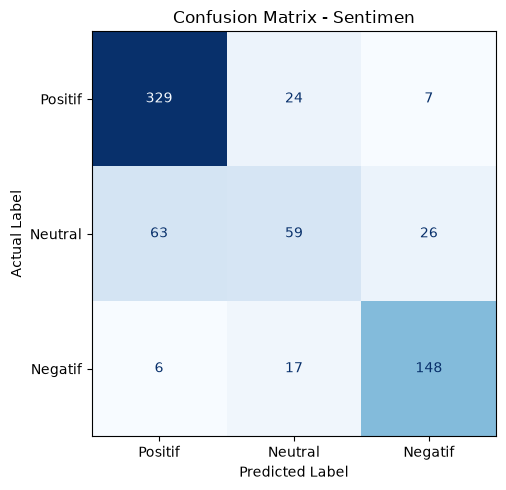


Sentimen News
Accuracy         : 0.6714
Macro Precision  : 0.6731
Macro Recall     : 0.6586
Macro F1-score   : 0.6631

Classification Report:
              precision    recall  f1-score   support

     Positif       0.74      0.66      0.70       327
     Neutral       0.48      0.58      0.52       249
     Negatif       0.80      0.74      0.77       404

   micro avg       0.68      0.67      0.68       980
   macro avg       0.67      0.66      0.66       980
weighted avg       0.70      0.67      0.68       980


Confusion Matrix:
                Predicted Positif  Predicted Neutral  Predicted Negatif
Actual Positif                215                 85                 22
Actual Neutral                 48                144                 53
Actual Negatif                 27                 72                299


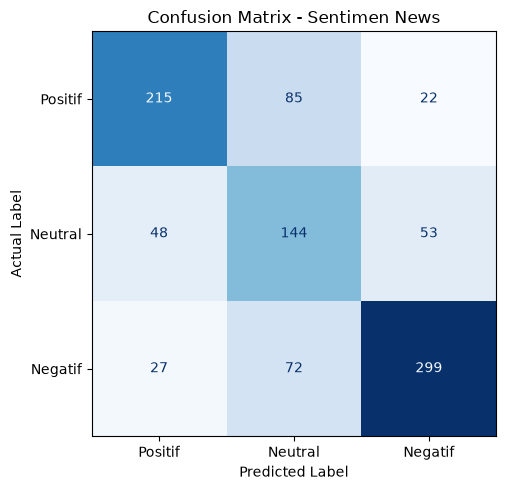


Combined Classification
Accuracy         : 0.7184
Macro Precision  : 0.7008
Macro Recall     : 0.6923
Macro F1-score   : 0.6964

Classification Report:
              precision    recall  f1-score   support

     Positif       0.79      0.79      0.79       688
     Neutral       0.51      0.51      0.51       398
     Negatif       0.81      0.78      0.79       576

   micro avg       0.73      0.72      0.72      1662
   macro avg       0.70      0.69      0.70      1662
weighted avg       0.73      0.72      0.72      1662


Confusion Matrix:
                Predicted Positif  Predicted Neutral  Predicted Negatif
Actual Positif                544                109                 29
Actual Neutral                111                203                 79
Actual Negatif                 33                 89                447


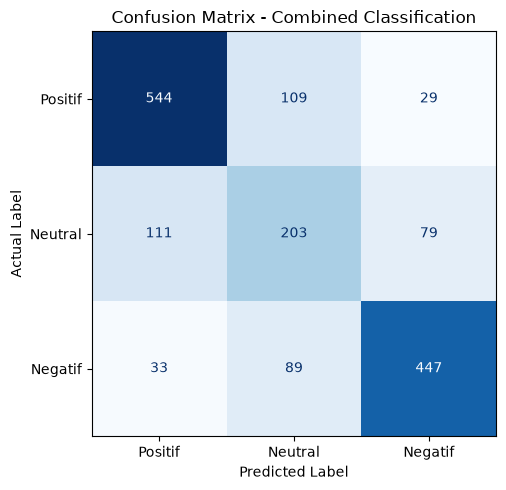


CLASSIFICATION SUMMARY


,Domain,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Sentimen,0.785924,0.744771,0.722599,0.726451
1,Sentimen News,0.671429,0.673083,0.658635,0.663065
2,Combined Classification,0.718412,0.700779,0.692263,0.696428


In [21]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

CLASS_LABELS = ["Positif", "Neutral", "Negatif"]

def evaluate_classification(data, domain_name):
    y_true = data["normalized_reference"]
    y_pred = data["normalized_prediction"]

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred,
        labels=CLASS_LABELS,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        labels=CLASS_LABELS,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        labels=CLASS_LABELS,
        average="macro",
        zero_division=0
    )

    print(f"\n{domain_name}")
    print("=" * 50)
    print(f"Accuracy         : {accuracy:.4f}")
    print(f"Macro Precision  : {precision:.4f}")
    print(f"Macro Recall     : {recall:.4f}")
    print(f"Macro F1-score   : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=CLASS_LABELS,
        zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_LABELS
    )

    print("\nConfusion Matrix:")
    print(pd.DataFrame(
        cm,
        index=[f"Actual {label}" for label in CLASS_LABELS],
        columns=[f"Predicted {label}" for label in CLASS_LABELS]
    ))

    # Plot Confusion Matrix
    fig, ax = plt.subplots(figsize=(7, 5))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_LABELS
    )

    display.plot(
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix - {domain_name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return {
        "Domain": domain_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-score": f1
    }


# Evaluate both classification domains separately
classification_results = []

for domain in CLASSIFICATION_DOMAINS:
    domain_data = classification_df[
        classification_df["domain"] == domain
    ]

    result = evaluate_classification(domain_data, domain)
    classification_results.append(result)


# Combined classification result
combined_result = evaluate_classification(
    classification_df,
    "Combined Classification"
)

classification_results.append(combined_result)


# Summary
classification_metrics_df = pd.DataFrame(classification_results)

print("\nCLASSIFICATION SUMMARY")
display(classification_metrics_df)


In [22]:

TEXT_DOMAINS = [
    "Campuran Kod",
    "Penukaran Kod",
    "Terjemahan"
]

print("TEXT GENERATION REFERENCE AUDIT")
print("=" * 60)

for domain in TEXT_DOMAINS:
    domain_data = text_df[text_df["domain"] == domain]

    print(f"\nDOMAIN: {domain}")
    print(f"Total records: {len(domain_data)}")

    # Count reference dictionary keys
    reference_keys = Counter()

    for reference in domain_data["reference"]:
        if isinstance(reference, dict):
            reference_keys.update(reference.keys())
        else:
            reference_keys.update(["Non-dictionary reference"])

    print("Reference fields:")
    for key, count in reference_keys.items():
        print(f"  {key}: {count}")

    # Check prediction availability
    empty_predictions = (
        domain_data["prediction_text"].eq("").sum()
    )

    print(f"Empty predictions: {empty_predictions}")

print("\nReference audit completed.")


TEXT GENERATION REFERENCE AUDIT

DOMAIN: Campuran Kod
Total records: 275
Reference fields:
  ujaran tidak formal: 275
  ujaran formal: 275
Empty predictions: 5

DOMAIN: Penukaran Kod
Total records: 799
Reference fields:
  jawapan formal: 799
  jawapan tidak formal: 799
Empty predictions: 6

DOMAIN: Terjemahan
Total records: 712
Reference fields:
  jawapan (bahasa sasaran): 712
Empty predictions: 16

Reference audit completed.


In [23]:
# Check prediction format without displaying dataset content

for domain in TEXT_DOMAINS:
    domain_data = text_df[text_df["domain"] == domain]

    print(f"\nDOMAIN: {domain}")
    print("=" * 50)

    # Check prediction length statistics
    prediction_lengths = domain_data[
        "prediction_text"
    ].str.len()

    print("Prediction length statistics:")
    print(prediction_lengths.describe())

    # Check how many predictions contain formal/informal markers
    predictions = domain_data["prediction_text"]

    formal_markers = predictions.str.contains(
        r"(?i)formal|rasmi|profesional",
        regex=True
    ).sum()

    informal_markers = predictions.str.contains(
        r"(?i)tidak formal|informal|santai|kasual",
        regex=True
    ).sum()

    print(f"Predictions containing formal markers: {formal_markers}")
    print(f"Predictions containing informal markers: {informal_markers}")

print("\nPrediction format audit completed.")



DOMAIN: Campuran Kod
Prediction length statistics:
count    275.000000
mean     249.774545
std       80.381436
min        0.000000
25%      210.000000
50%      244.000000
75%      300.500000
max      642.000000
Name: prediction_text, dtype: float64
Predictions containing formal markers: 270
Predictions containing informal markers: 269

DOMAIN: Penukaran Kod
Prediction length statistics:
count    799.000000
mean     344.629537
std      122.542164
min        0.000000
25%      257.000000
50%      336.000000
75%      420.500000
max      793.000000
Name: prediction_text, dtype: float64
Predictions containing formal markers: 793
Predictions containing informal markers: 793

DOMAIN: Terjemahan
Prediction length statistics:
count    712.000000
mean     249.668539
std      121.624840
min        0.000000
25%      168.000000
50%      228.000000
75%      312.250000
max      979.000000
Name: prediction_text, dtype: float64
Predictions containing formal markers: 19
Predictions containing informal m

In [24]:
import re

def detect_output_format(text):
    if not text.strip():
        return "EMPTY"

    has_formal = bool(re.search(
        r"(?im)^\s*(?:\*\*)?(?:jawapan\s+)?formal\s*:?",
        text
    ))

    has_informal = bool(re.search(
        r"(?im)^\s*(?:\*\*)?(?:jawapan\s+)?(?:tidak\s+formal|informal)\s*:?",
        text
    ))

    if has_formal and has_informal:
        return "BOTH_LABELS"
    elif has_formal:
        return "FORMAL_ONLY"
    elif has_informal:
        return "INFORMAL_ONLY"
    else:
        return "NO_CLEAR_LABELS"


for domain in ["Campuran Kod", "Penukaran Kod"]:
    domain_data = text_df[text_df["domain"] == domain]

    format_counts = domain_data["prediction_text"].apply(
        detect_output_format
    ).value_counts()

    print(f"\n{domain}")
    print("=" * 50)
    print(format_counts)


Campuran Kod
prediction_text
BOTH_LABELS    269
EMPTY            5
FORMAL_ONLY      1
Name: count, dtype: int64

Penukaran Kod
prediction_text
BOTH_LABELS    793
EMPTY            6
Name: count, dtype: int64


In [25]:
import re

def extract_style_answers(text):
    result = {
        "formal": None,
        "informal": None
    }

    if not text or not text.strip():
        return result

    # Locate formal and informal sections
    pattern = re.compile(
        r"(?im)^\s*(?:\*\*)?(?:jawapan\s+)?"
        r"(formal|tidak\s+formal|informal)"
        r"(?:\*\*)?\s*:\s*"
    )

    matches = list(pattern.finditer(text))

    for i, match in enumerate(matches):
        label = match.group(1).lower().strip()

        start = match.end()
        end = (
            matches[i + 1].start()
            if i + 1 < len(matches)
            else len(text)
        )

        answer = text[start:end].strip()

        if label == "formal":
            result["formal"] = answer
        else:
            result["informal"] = answer

    return result


# Extract answers for both domains
style_data = text_df[
    text_df["domain"].isin(["Campuran Kod", "Penukaran Kod"])
].copy()

style_data["extracted"] = style_data["prediction_text"].apply(
    extract_style_answers
)

style_data["pred_formal"] = style_data["extracted"].apply(
    lambda x: x["formal"] or ""
)

style_data["pred_informal"] = style_data["extracted"].apply(
    lambda x: x["informal"] or ""
)

print("STYLE EXTRACTION AUDIT")
print("=" * 50)

for domain in ["Campuran Kod", "Penukaran Kod"]:
    subset = style_data[style_data["domain"] == domain]

    print(f"\n{domain}")
    print(f"Total records: {len(subset)}")
    print(f"Formal extracted: {(subset['pred_formal'] != '').sum()}")
    print(f"Informal extracted: {(subset['pred_informal'] != '').sum()}")

print("\nStyle extraction completed.")


STYLE EXTRACTION AUDIT

Campuran Kod
Total records: 275
Formal extracted: 270
Informal extracted: 269

Penukaran Kod
Total records: 799
Formal extracted: 793
Informal extracted: 792

Style extraction completed.


In [26]:

def extraction_status(row):
    has_formal = bool(row["pred_formal"].strip())
    has_informal = bool(row["pred_informal"].strip())

    if has_formal and has_informal:
        return "COMPLETE"
    elif has_formal or has_informal:
        return "PARTIAL"
    else:
        return "EMPTY"


style_data["extraction_status"] = style_data.apply(
    extraction_status,
    axis=1
)

print("EXTRACTION COMPLETENESS AUDIT")
print("=" * 50)

for domain in ["Campuran Kod", "Penukaran Kod"]:
    subset = style_data[style_data["domain"] == domain]

    print(f"\n{domain}")
    print(
        subset["extraction_status"]
        .value_counts()
        .reindex(["COMPLETE", "PARTIAL", "EMPTY"], fill_value=0)
    )

print("\nOverall:")
print(style_data["extraction_status"].value_counts())


EXTRACTION COMPLETENESS AUDIT

Campuran Kod
extraction_status
COMPLETE    269
PARTIAL       1
EMPTY         5
Name: count, dtype: int64

Penukaran Kod
extraction_status
COMPLETE    792
PARTIAL       1
EMPTY         6
Name: count, dtype: int64

Overall:
extraction_status
COMPLETE    1061
EMPTY         11
PARTIAL        2
Name: count, dtype: int64


In [27]:
# Extract references for formal and informal responses

def get_reference_value(data, key):
    if isinstance(data, dict):
        value = data.get(key)
        return str(value).strip() if value is not None else ""
    return ""


# Map reference keys by domain
formal_reference_keys = {
    "Campuran Kod": "ujaran formal",
    "Penukaran Kod": "jawapan formal"
}

informal_reference_keys = {
    "Campuran Kod": "ujaran tidak formal",
    "Penukaran Kod": "jawapan tidak formal"
}

style_data["ref_formal"] = style_data.apply(
    lambda row: get_reference_value(
        row["reference"],
        formal_reference_keys[row["domain"]]
    ),
    axis=1
)

style_data["ref_informal"] = style_data.apply(
    lambda row: get_reference_value(
        row["reference"],
        informal_reference_keys[row["domain"]]
    ),
    axis=1
)

# Check reference and prediction availability
print("REFERENCE-PREDICTION PAIR AUDIT")
print("=" * 50)

for domain in ["Campuran Kod", "Penukaran Kod"]:
    subset = style_data[style_data["domain"] == domain]

    print(f"\n{domain}")
    print(f"Total records: {len(subset)}")

    print(
        "Missing formal reference:",
        (subset["ref_formal"] == "").sum()
    )

    print(
        "Missing informal reference:",
        (subset["ref_informal"] == "").sum()
    )

    print(
        "Missing formal prediction:",
        (subset["pred_formal"] == "").sum()
    )

    print(
        "Missing informal prediction:",
        (subset["pred_informal"] == "").sum()
    )

print("\nReference-prediction pairing completed.")


REFERENCE-PREDICTION PAIR AUDIT

Campuran Kod
Total records: 275
Missing formal reference: 0
Missing informal reference: 174
Missing formal prediction: 5
Missing informal prediction: 6

Penukaran Kod
Total records: 799
Missing formal reference: 0
Missing informal reference: 0
Missing formal prediction: 6
Missing informal prediction: 7

Reference-prediction pairing completed.


In [28]:

campuran_data = text_df[
    text_df["domain"] == "Campuran Kod"
]

reference_key_audit = Counter()
informal_value_status = Counter()

for reference in campuran_data["reference"]:
    if isinstance(reference, dict):
        reference_key_audit.update(reference.keys())

        if "ujaran tidak formal" in reference:
            value = reference["ujaran tidak formal"]

            if value is None:
                informal_value_status["None"] += 1
            elif str(value).strip() == "":
                informal_value_status["Empty string"] += 1
            else:
                informal_value_status["Has value"] += 1
        else:
            informal_value_status["Key missing"] += 1

print("CAMPURAN KOD REFERENCE KEY AUDIT")
print("=" * 50)

print("\nReference keys:")
for key, count in reference_key_audit.items():
    print(f"{key}: {count}")

print("\nInformal reference value status:")
for status, count in informal_value_status.items():
    print(f"{status}: {count}")


CAMPURAN KOD REFERENCE KEY AUDIT

Reference keys:
ujaran tidak formal: 275
ujaran formal: 275

Informal reference value status:
Has value: 101
None: 174


In [29]:
print("REFERENCE COVERAGE")
print("=" * 50)

for domain in ["Campuran Kod", "Penukaran Kod"]:
    subset = style_data[style_data["domain"] == domain]

    for style in ["formal", "informal"]:
        ref_col = f"ref_{style}"

        available = (subset[ref_col] != "").sum()
        total = len(subset)
        coverage = available / total * 100

        print(
            f"{domain} | {style.title()}: "
            f"{available}/{total} ({coverage:.2f}%)"
        )


REFERENCE COVERAGE
Campuran Kod | Formal: 275/275 (100.00%)
Campuran Kod | Informal: 101/275 (36.73%)
Penukaran Kod | Formal: 799/799 (100.00%)
Penukaran Kod | Informal: 799/799 (100.00%)


In [45]:
# STEP 1: Audit translation dataset structure

translation_df = gemma_df[
    gemma_df["domain"] == "Terjemahan"
].copy()

print("Total translation records:", len(translation_df))

print("\nInput keys:")
print(
    translation_df["input"].apply(
        lambda x: tuple(x.keys()) if isinstance(x, dict) else type(x).__name__
    ).value_counts()
)

print("\nReference keys:")
print(
    translation_df["reference"].apply(
        lambda x: tuple(x.keys()) if isinstance(x, dict) else type(x).__name__
    ).value_counts()
)

print("\nPrediction availability:")
print(
    "Non-empty:",
    translation_df["prediction"].fillna("").str.strip().ne("").sum()
)
print(
    "Empty:",
    translation_df["prediction"].fillna("").str.strip().eq("").sum()
)

Total translation records: 712

Input keys:
input
(soalan (bahasa sumber),)    712
Name: count, dtype: int64

Reference keys:
reference
(jawapan (bahasa sasaran),)    712
Name: count, dtype: int64

Prediction availability:
Non-empty: 696
Empty: 16


In [46]:
# STEP 2: Prepare translation evaluation data

translation_eval_df = translation_df.copy()

translation_eval_df["input_translation"] = (
    translation_eval_df["input"].apply(
        lambda x: x.get("soalan (bahasa sumber)")
        if isinstance(x, dict) else None
    )
)

translation_eval_df["ref_translation"] = (
    translation_eval_df["reference"].apply(
        lambda x: x.get("jawapan (bahasa sasaran)")
        if isinstance(x, dict) else None
    )
)

translation_eval_df["pred_translation"] = (
    translation_eval_df["prediction"].fillna("").astype(str)
)

print("Translation evaluation dataset prepared.")
print("Total records:", len(translation_eval_df))

print("\nMissing input:",
      translation_eval_df["input_translation"].isna().sum())

print("Missing reference:",
      translation_eval_df["ref_translation"].isna().sum())

print("Empty predictions:",
      translation_eval_df["pred_translation"].str.strip().eq("").sum())

print("\nColumns:")
print(translation_eval_df.columns.tolist())

Translation evaluation dataset prepared.
Total records: 712

Missing input: 0
Missing reference: 0
Empty predictions: 16

Columns:
['record_id', 'source_excel_row', 'domain', 'input', 'reference', 'prediction', 'inference_time', 'status', 'input_text', 'reference_text', 'prediction_text', 'input_translation', 'ref_translation', 'pred_translation']


In [30]:
try:
    import sacrebleu
    print("sacrebleu version:", sacrebleu.__version__)
    print("Library available. Ready for evaluation.")

except ImportError:
    print("sacrebleu is not installed.")
    print("Run: pip install sacrebleu")


sacrebleu version: 2.6.0
Library available. Ready for evaluation.


In [32]:
try:
    import bert_score
    print("BERTScore is installed.")
    print("Version:", bert_score.__version__)

except ImportError:
    print("BERTScore is not installed.")
    print("Run: pip install bert-score")


BERTScore is installed.
Version: 0.3.12


In [34]:
import transformers
import torch

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

Transformers version: 5.22.1
PyTorch version: 2.9.1+rocm7.2.1
Device: GPU


In [37]:
import transformers
import inspect

print("Transformers:", transformers.__version__)

print("\nTokenizer classes available:")

for name in [
    "XLMRobertaTokenizer",
    "XLMRobertaTokenizerFast"
]:
    cls = getattr(transformers, name, None)

    print(f"\n{name}:")
    print("Available:", cls is not None)

    if cls is not None:
        print("Class:", cls)
        print("Module:", inspect.getmodule(cls))


Transformers: 5.22.1

Tokenizer classes available:

XLMRobertaTokenizer:
Available: True
Class: <class 'transformers.models.xlm_roberta.tokenization_xlm_roberta.XLMRobertaTokenizer'>
Module: <module 'transformers.models.xlm_roberta.tokenization_xlm_roberta' from 'C:\\AI\\rocm-env\\Lib\\site-packages\\transformers\\models\\xlm_roberta\\tokenization_xlm_roberta.py'>

XLMRobertaTokenizerFast:
Available: True
Class: <class 'transformers.models.xlm_roberta.tokenization_xlm_roberta.XLMRobertaTokenizer'>
Module: <module 'transformers.models.xlm_roberta.tokenization_xlm_roberta' from 'C:\\AI\\rocm-env\\Lib\\site-packages\\transformers\\models\\xlm_roberta\\tokenization_xlm_roberta.py'>


In [40]:
import transformers
import transformers.models.xlm_roberta as xlm

print("XLM-R module:", xlm.__file__)

print("\nAvailable tokenizer-related attributes:")

for name in dir(xlm):
    if "Tokenizer" in name:
        print(name)


XLM-R module: C:\AI\rocm-env\Lib\site-packages\transformers\models\xlm_roberta\__init__.py

Available tokenizer-related attributes:
XLMRobertaTokenizer


In [38]:
try:
    import tokenizers
    from tokenizers import Tokenizer

    print("Tokenizers version:", tokenizers.__version__)
    print("Fast tokenizer backend available:", True)

except ImportError as e:
    print("Fast tokenizer backend available:", False)
    print("Error:", e)


Tokenizers version: 0.23.3
Fast tokenizer backend available: True


In [41]:
import importlib.metadata as metadata

packages = [
    "transformers",
    "tokenizers",
    "bert-score",
    "torch",
    "huggingface-hub"
]

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: Not installed")


transformers: 5.22.1
tokenizers: 0.23.3
bert-score: 0.3.13
torch: 2.9.1+rocm7.2.1
huggingface-hub: 2.4.0


In [42]:
import inspect
from bert_score import utils

print("BERTScore tokenizer implementation:")
print(inspect.getsource(utils.sent_encode))


BERTScore tokenizer implementation:
def sent_encode(tokenizer, sent):
    "Encoding as sentence based on the tokenizer"
    sent = sent.strip()
    if sent == "":
        return tokenizer.build_inputs_with_special_tokens([])
    elif isinstance(tokenizer, GPT2Tokenizer) or isinstance(tokenizer, RobertaTokenizer):
        # for RoBERTa and GPT-2
        if version.parse(trans_version) >= version.parse("4.0.0"):
            return tokenizer.encode(
                sent,
                add_special_tokens=True,
                add_prefix_space=True,
                max_length=tokenizer.model_max_length,
                truncation=True,
            )
        elif version.parse(trans_version) >= version.parse("3.0.0"):
            return tokenizer.encode(
                sent,
                add_special_tokens=True,
                add_prefix_space=True,
                max_length=tokenizer.max_len,
                truncation=True,
            )
        elif version.parse(trans_version) >=

In [47]:
import re
import pandas as pd
import sacrebleu
import unicodedata
from bert_score import score as bert_score

# BERTScore configuration
BERT_MODEL = "xlm-roberta-large"
BERT_BATCH_SIZE = 16


def normalize_text(text):
    text = str(text).lower().strip()
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", "", text)
    return text.strip()


def evaluate_text_generation(data, domain, style=None):

    # Select the appropriate reference and prediction columns
    if domain == "Terjemahan":
        ref_col = "ref_translation"
        pred_col = "pred_translation"
        style_label = "Translation"

    else:
        ref_col = f"ref_{style}"
        pred_col = f"pred_{style}"
        style_label = style.title()

    # Keep records with available references
    valid_reference = (
        data[ref_col].fillna("").astype(str).str.strip().ne("")
    )

    evaluation_data = data[valid_reference].copy()

    references = evaluation_data[ref_col].tolist()
    predictions = evaluation_data[pred_col].fillna("").tolist()

    if not references:
        raise ValueError(
            f"No available references for {domain} - {style_label}"
        )

    # Exact Match
    exact_matches = [
        normalize_text(pred) == normalize_text(ref)
        for pred, ref in zip(predictions, references)
    ]

    exact_match = sum(exact_matches) / len(references) * 100

    # BLEU
    bleu = sacrebleu.corpus_bleu(
        predictions,
        [references]
    )

    # chrF++
    chrf = sacrebleu.corpus_chrf(
        predictions,
        [references],
        word_order=2
    )

    # BERTScore
    non_empty_indices = [
        i for i, pred in enumerate(predictions)
        if str(pred).strip()
    ]

    bert_precision_scores = [0.0] * len(predictions)
    bert_recall_scores = [0.0] * len(predictions)
    bert_f1_scores = [0.0] * len(predictions)

    if non_empty_indices:
        valid_predictions = [
            predictions[i] for i in non_empty_indices
        ]

        valid_references = [
            references[i] for i in non_empty_indices
        ]

        P, R, F1 = bert_score(
            valid_predictions,
            valid_references,
            model_type=BERT_MODEL,
            batch_size=BERT_BATCH_SIZE,
            verbose=True
        )

        for position, original_index in enumerate(non_empty_indices):
            bert_precision_scores[original_index] = P[position].item()
            bert_recall_scores[original_index] = R[position].item()
            bert_f1_scores[original_index] = F1[position].item()

    bert_precision = sum(bert_precision_scores) / len(predictions)
    bert_recall = sum(bert_recall_scores) / len(predictions)
    bert_f1 = sum(bert_f1_scores) / len(predictions)

    # Prediction availability
    empty_predictions = sum(
        not str(pred).strip() for pred in predictions
    )

    return {
        "Domain": domain,
        "Style": style_label,
        "Total Records": len(data),
        "Reference Available": len(evaluation_data),
        "Reference Coverage (%)": round(
            len(evaluation_data) / len(data) * 100, 2
        ),
        "Successful Predictions": len(predictions) - empty_predictions,
        "Empty Predictions": empty_predictions,
        "Prediction Coverage (%)": round(
            (len(predictions) - empty_predictions)
            / len(predictions) * 100, 2
        ),
        "Exact Match (%)": round(exact_match, 2),
        "BLEU": round(bleu.score, 2),
        "chrF++": round(chrf.score, 2),
        "BERTScore Precision": round(bert_precision, 4),
        "BERTScore Recall": round(bert_recall, 4),
        "BERTScore F1": round(bert_f1, 4)
    }


# Run evaluation
text_evaluation_results = []

# Campuran Kod and Penukaran Kod
for domain in ["Campuran Kod", "Penukaran Kod"]:

    domain_data = style_data[
        style_data["domain"] == domain
    ]

    for style in ["formal", "informal"]:

        print(f"\nEvaluating: {domain} - {style.title()}")

        result = evaluate_text_generation(
            domain_data,
            domain,
            style
        )

        text_evaluation_results.append(result)


# Translation
print("\nEvaluating: Terjemahan")

translation_result = evaluate_text_generation(
    translation_eval_df,
    "Terjemahan"
)

text_evaluation_results.append(translation_result)


# Display results
text_metrics_df = pd.DataFrame(text_evaluation_results)

print("\nTEXT GENERATION EVALUATION RESULTS")
print("=" * 70)

display(text_metrics_df)



Evaluating: Campuran Kod - Formal


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 872.63it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-large
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


calculating scores...
computing bert embedding.


100%|██████████| 34/34 [00:10<00:00,  3.26it/s]


computing greedy matching.


100%|██████████| 17/17 [00:00<00:00, 188.49it/s]


... (22 outputs left out)

computing greedy matching.


100%|██████████| 44/44 [00:00<00:00, 181.23it/s]


done in 36.12 seconds, 19.27 sentences/sec

TEXT GENERATION EVALUATION RESULTS


,Domain,Style,Total Records,Reference Available,Reference Coverage (%),Successful Predictions,Empty Predictions,Prediction Coverage (%),Exact Match (%),BLEU,chrF++,BERTScore Precision,BERTScore Recall,BERTScore F1
0,Campuran Kod,Formal,275,275,100.00,270,5,98.18,0.00,2.34,20.63,0.8830,0.8702,0.8763
1,Campuran Kod,Informal,275,101,36.73,101,0,100.00,0.00,4.40,25.01,0.9033,0.9042,0.9036
2,Penukaran Kod,Formal,799,799,100.00,793,6,99.25,0.00,2.95,22.48,0.8881,0.8755,0.8814
3,Penukaran Kod,Informal,799,799,100.00,792,7,99.12,0.00,1.14,15.52,0.8814,0.8651,0.8729
4,Terjemahan,Translation,712,712,100.00,696,16,97.75,0.28,37.06,60.98,0.9373,0.9356,0.9363


In [48]:
from pathlib import Path

EVAL_DIR = Path(
    r"C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\gemma\prompt_v2\evaluation"
)

EVAL_DIR.mkdir(parents=True, exist_ok=True)

text_metrics_df.to_csv(
    EVAL_DIR / "gemma_v2_text_generation_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Gemma V2 text generation metrics saved!")
print("Location:", EVAL_DIR)

Gemma V2 text generation metrics saved!
Location: C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\gemma\prompt_v2\evaluation
